In [1]:
# Google Colab Only
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval dataeval-plots maite-datasets
except Exception:
    pass

In [2]:
import logging
import warnings

from dataeval.exceptions import ExperimentalWarning

# Feasibility and its evidence types are experimental; the tutorial says so once instead of warning in every cell.
warnings.filterwarnings("ignore", category=ExperimentalWarning)

In [3]:
import dataeval_plots as dep
import numpy as np
import torch
from maite_datasets.image_classification import MilitaryVehicles
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import radius_neighbors_graph
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torchvision.models import ViT_B_16_Weights, vit_b_16

from dataeval import Embeddings, Metadata, Ontology
from dataeval.data import Indices, Relabel, View
from dataeval.extractors import TorchExtractor
from dataeval.performance import Feasibility, TargetSpec
from dataeval.quality import Duplicates

In [4]:
# MilitaryVehicles downloads through huggingface_hub, which logs a warning for each rate-limited (HTTP 429)
# request it retries; maite-datasets already retries and reports progress. Set after the imports, because
# importing huggingface_hub resets its logger to WARNING.
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

In [5]:
train = MilitaryVehicles(root="./data", image_set="train", download=True)
test = MilitaryVehicles(root="./data", image_set="test", download=True)
print(f"Training split: {len(train):,} images. Test split: {len(test):,} images.")
print(f"Vehicle types: {len(test.index2label)}")

Training split: 7,823 images. Test split: 1,621 images.
Vehicle types: 24


In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
weights = ViT_B_16_Weights.DEFAULT
backbone = vit_b_16(weights=weights, progress=False)
backbone.heads = torch.nn.Sequential()  # an empty head keeps the 768-dimensional embedding, not a 1,000-class answer
extractor = TorchExtractor(backbone, transforms=weights.transforms(), device=device)

train_x = np.asarray(Embeddings(train, extractor=extractor, batch_size=128))
test_x = np.asarray(Embeddings(test, extractor=extractor, batch_size=128))
print(f"Each image is now a {train_x.shape[1]}-dimensional embedding")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


Each image is now a 768-dimensional embedding


In [7]:
# TEST ASSERTION CELL ###
assert (len(train), len(test), len(test.index2label)) == (7823, 1621, 24)
assert train_x.shape == (7823, 768)
assert test_x.shape == (1621, 768)

In [8]:
# DataEval's duplicate search, over both splits: each row is a group of repeats with matching fingerprints
found = Duplicates(hash_radius=0).evaluate(train, test).data()
pairs = []
for items, splits in zip(found["item_indices"], found["dataset_indices"], strict=True):
    ids = [item + split * len(train) for item, split in zip(items, splits, strict=True)]  # number training images first
    pairs += [(ids[0], other) for other in ids[1:]]

# Embeddings at cosine similarity >= 0.95, which for embeddings scaled to length 1 is a distance <= sqrt(2 - 2 * 0.95)
unit_embeddings = np.vstack([train_x, test_x])
unit_embeddings /= np.linalg.norm(unit_embeddings, axis=1, keepdims=True)
links = radius_neighbors_graph(unit_embeddings, radius=np.sqrt(2 - 2 * 0.95))
links = links + coo_matrix((np.ones(len(pairs)), tuple(zip(*pairs, strict=True))), shape=links.shape)

# A family is every image linked to another by either kind of repeat
_, family = connected_components(links, directed=False)
train_family, test_family = family[: len(train)], family[len(train) :]

repeats_training = np.isin(test_family, train_family)
first_of_family = np.unique(test_family, return_index=True)[1]
keep = np.sort(first_of_family[~repeats_training[first_of_family]])
repeats_test = len(test) - repeats_training.sum() - len(keep)
print(f"Removed {repeats_training.sum()} test images that repeat a training image")
print(f"Removed {repeats_test} test images that repeat another test image")
print(f"Kept {len(keep):,} test images")

Removed 135 test images that repeat a training image
Removed 9 test images that repeat another test image
Kept 1,477 test images


In [9]:
# TEST ASSERTION CELL ###
# Counts at the cosine-0.95 boundary move a little with the GPU, so they are checked in bands the prose stays true in
removed = len(test) - len(keep)
assert 0.08 <= removed / len(test) < 0.10  # "about 9% of the test split"
assert repeats_training.sum() > 2 * repeats_test  # "most of it because it repeats a training image"
assert 1460 <= len(keep) <= 1500  # "about 1,480"
assert len(np.unique(test_family[keep])) == len(keep)  # one image per family
assert not np.isin(test_family[keep], train_family).any()  # no family shared with training

In [10]:
train_y = np.asarray(Metadata(train).class_labels)
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
fit_rows, calibration_rows = next(split.split(train_x, groups=train_family))

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
model.fit(train_x[fit_rows], train_y[fit_rows])
scores = model.predict_proba(test_x)  # one row per test image, one score per vehicle type
print(f"Trained on {len(fit_rows):,} images; {len(calibration_rows):,} calibration images set aside")

Trained on 6,254 images; 1,569 calibration images set aside


In [11]:
# TEST ASSERTION CELL ###
assert 0.18 < len(calibration_rows) / len(train) < 0.22  # "about one fifth", by family
assert not np.isin(train_family[calibration_rows], train_family[fit_rows]).any()  # families stay on one side
assert model.classes_.tolist() == list(range(24))  # score columns are the vehicle types in index order

In [12]:
feasibility = Feasibility(alpha=0.05 / 3, seed=42)  # for all three planned calls: a third of the budget each, one seed

In [13]:
types = View(test, [Indices(keep)])
provenance = {
    "reads": "representation",
    "frozen_before_audit": True,
    "selection": (
        "ViT-B/16 chosen by 5-fold cross-validation on the training split; logistic regression not tuned; an earlier "
        "exploratory comparison scored the three backbones on these test images"
    ),
    "preprocessing": "ViT-B/16 class-token embeddings, standardized",
}

type_result = feasibility.evaluate(
    types, target={"accuracy": 0.60}, embeddings=test_x[keep], predictions=scores[keep], provenance=provenance
)
print(type_result)

Feasibility of 1 requirement, judged for models that may use the whole image.
All bounds hold together at 98.3% confidence, for new images from the same population.
They assume no evaluation image was used to train or choose a model, or to set a requirement.

Requirement    Determination             Lower confidence bound   Upper confidence bound
60% accuracy   insufficient evidence ?   43.2% (your model)       —

Next
  60% accuracy  more evaluation images would not help at the observed scores;
                to show it, test a stronger model;
                to rule it out, collect repeated labels for a whole-image ceiling

Notes
  Your model scored 48.2% accuracy on 739 evaluation images.
  Group-based ceiling (56.4% accuracy) bounds only models that give one answer per group.


In [14]:
# TEST ASSERTION CELL ###
NO_GAIN = "more evaluation images would not help at the observed scores;"  # quoted below
NEXT = "to show it, test a stronger model; to rule it out, collect repeated labels for a whole-image ceiling"
row = type_result.determinations.row(0, named=True)
assert (row["determination"], row["witness_source"], row["ceiling"]) == ("unresolved", "user_witness/v1", None)
assert row["suggested_minimum"] is None
printed = str(type_result)
flat = " ".join(printed.split())  # Next lines wrap after their semicolons
assert "All bounds hold together at 98.3% confidence" in printed
assert "They assume no evaluation image was used to train or choose a model, or to set a requirement." in printed
assert f"60% accuracy {NO_GAIN} {NEXT}" in flat
assert "accuracy) bounds only models that give one answer per group." in printed  # the group-based ceiling note
bounds = type_result.aggregate_by_evidence()
yours = bounds.filter(source="your model").row(0, named=True)
EVALUATION = len(keep) - round(len(keep) / 2)  # Feasibility fits on half the kept images and evaluates on the rest
assert yours["n"] == EVALUATION
assert 730 <= EVALUATION <= 750  # "about 740"
# A family count that moves at the cosine-0.95 boundary redraws the evaluation images; the bands cover such redraws
assert 0.44 < yours["observed"] < 0.56  # "about half"
assert 0.39 < row["witness"] < 0.48  # "roughly 40 to 45%"
group_based = bounds.filter(source="group-based ceiling")["bound"].item()
assert 0.51 < group_based < 0.60  # "about 55%"; below 60%, so it "would rule that out" at its scope

In [15]:
ontology = Ontology.from_hierarchy(test.hierarchy)
categories = ontology.children("land vehicle")
to_category = {vehicle: category for category in categories for vehicle in ontology.subtree_ids(category)}
relabel = Relabel(to_category, target=categories)

by_category = View(test, [Indices(keep), relabel])
category_scores = relabel.fold_scores(scores, view=by_category)  # one row per kept image, one score per category

category_result = feasibility.evaluate(
    by_category, target={"accuracy": 0.60}, embeddings=test_x[keep], predictions=category_scores, provenance=provenance
)
print(category_result)

Feasibility of 1 requirement, judged for models that may use the whole image.
All bounds hold together at 98.3% confidence, for new images from the same population.
They assume no evaluation image was used to train or choose a model, or to set a requirement.

Requirement    Determination    Lower confidence bound   Upper confidence bound
60% accuracy   demonstrated ✓   65.5% (your model)       —

Notes
  Your model scored 70.2% accuracy on 739 evaluation images.
  Group-based ceiling (76.1% accuracy) bounds only models that give one answer per group.


In [16]:
# TEST ASSERTION CELL ###
assert categories == ("Tank", "BMP", "BTR", "Self Propelled Artillery", "Air Defense", "MT LB", "BMD")
assert sum(to_category[name] == "Tank" for name in test.index2label.values()) == 6  # "the six tank types"
assert category_scores.shape == (len(keep), 7)
row = category_result.determinations.row(0, named=True)
assert (row["determination"], row["witness_source"]) == ("demonstrated_feasible", "user_witness/v1")
assert 0.62 <= row["witness"] < 0.69  # "at least about 65%"
yours = category_result.aggregate_by_evidence().filter(source="your model").row(0, named=True)
assert yours["n"] == EVALUATION
assert 0.65 < yours["observed"] < 0.74  # "about 70%"

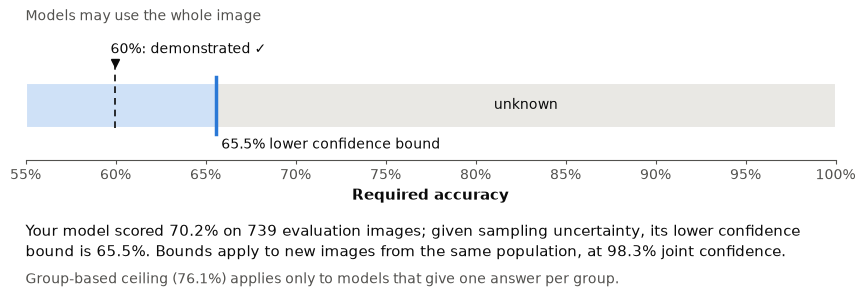

In [17]:
dep.plot(category_result)

In [18]:
TANK = categories.index("Tank")
assert train.index2label == test.index2label  # both splits number the 24 types the same way
category_of_type = np.array([categories.index(to_category[name]) for name in train.index2label.values()])
is_tank = category_of_type[train_y[calibration_rows]] == TANK
calibration_scores = relabel.fold_scores(model.predict_proba(train_x[calibration_rows]))
tank_score = calibration_scores[:, TANK]

# The declared rule: the lowest threshold that calls at most 2.5% of the calibration non-tanks tanks
candidates = np.unique(tank_score)
false_alarms = (tank_score[~is_tank] >= candidates[:, None]).mean(axis=1)
threshold = candidates[np.argmax(false_alarms <= 0.025)]


def report(says_tank, rule):
    """Print the share of calibration tanks a rule finds, and of other vehicles it calls tanks."""
    print(f"{rule}: finds {says_tank[is_tank].mean():.1%} of the calibration tanks, ", end="")
    print(f"calls {says_tank[~is_tank].mean():.1%} of the other vehicles tanks")


report(calibration_scores.argmax(axis=1) == TANK, "Highest score wins")
report(tank_score >= threshold, f"Tank score >= {threshold:.4f}")

Highest score wins: finds 78.9% of the calibration tanks, calls 9.9% of the other vehicles tanks
Tank score >= 0.9558: finds 48.9% of the calibration tanks, calls 2.5% of the other vehicles tanks


In [19]:
# TEST ASSERTION CELL ###
highest = calibration_scores.argmax(axis=1) == TANK
# A family count that moves at the cosine-0.95 boundary redraws the calibration split; the bands cover such redraws
assert 0.74 < highest[is_tank].mean() < 0.86  # "about 80% of the tanks"
assert 0.07 < highest[~is_tank].mean() < 0.12  # "about 10% of the other vehicles"
assert 0.02 < false_alarms[candidates == threshold].item() <= 0.025  # "2.5% or just under"
assert false_alarms[candidates < threshold].min() > 0.025  # the lowest threshold that meets the rule
assert 0.40 < (tank_score[is_tank] >= threshold).mean() < 0.60  # "only about half of the tanks"

In [20]:
def decide(folded):
    """Tank when the Tank score reaches the threshold; otherwise the highest-scoring other category."""
    others = folded.copy()
    others[:, TANK] = -np.inf
    return np.where(folded[:, TANK] >= threshold, TANK, others.argmax(axis=1))


tank_requirement = TargetSpec(
    task="IC", metric="recall", threshold=0.90, class_name="Tank", max_false_positive_rate=0.05
)
tank_provenance = provenance | {
    "decision_policy": (
        f"Tank (index {TANK}) when the summed Tank score is at least {threshold}, otherwise the highest-scoring "
        "other category; the threshold is the lowest whose false-positive rate on a calibration fifth of the "
        "training split, held out by near-duplicate family, is at most 2.5%"
    )
}

tank_result = feasibility.evaluate(
    by_category,
    target=[tank_requirement],
    embeddings=test_x[keep],
    predictions=decide(category_scores),
    provenance=tank_provenance,
)
print(tank_result)

Feasibility of 1 requirement, judged for models that may use the whole image.
All bounds hold together at 98.3% confidence, for new images from the same population.
They assume no evaluation image was used to train or choose a model, or to set a requirement.

Requirement                              Determination             Lower confidence bound                             Upper confidence bound
Tank: ≥90% recall, ≤5% false positives   insufficient evidence ?   recall 41.9%, FP ≤7.4% (your model, not counted)   —

Next
  Tank  more evaluation images would not help at the observed scores;
        to show it, test a stronger model or a different frozen operating point;
        to rule it out, collect repeated labels for a whole-image ceiling

Notes
  Your model scored 54.2% recall on 144 Tank images and 4.4% false positives on 595 other images.
  Tank: no tested model counts, since none keeps false positives within 5%;
    your model's upper confidence bound on false positives is 7.4%.

In [21]:
# TEST ASSERTION CELL ###
row = tank_result.determinations.row(0, named=True)
assert row["determination"] == "unresolved"
assert (row["ceiling"], row["suggested_minimum"]) == (None, None)
printed = str(tank_result)
assert "Tank: ≥90% recall, ≤5% false positives   insufficient evidence ?" in printed
TANK_NEXT = NEXT.replace("model;", "model or a different frozen operating point;")
assert f"Tank {NO_GAIN} {TANK_NEXT}" in " ".join(printed.split())
yours = tank_result.aggregate_by_evidence().filter(source="your model")
assert yours["quantity"].to_list() == ["recall", "false_positive_rate"]
tanks, others = yours["n"].to_list()
assert tanks + others == EVALUATION
assert 560 <= others <= 640  # "about 600 other vehicles"
assert 0.38 < yours["observed"][0] < 0.62  # "only about half of the tanks"
assert 0.01 < yours["observed"][1] < 0.05  # "a few percent"
# "close to the 5% limit": a redraw of the evaluation images can land it on either side, which the prose covers
assert 0.03 < yours["bound"][1] < 0.08
counted = row["witness_source"] == "user_witness/v1"
assert counted == (yours["bound"][1] <= 0.05)  # counted exactly when false alarms are shown within the limit
assert "FP ≤" in printed  # "shows both of the rule's numbers either way"
assert ("(your model, not counted)" in printed) != counted  # "above 5%, it marks them 'not counted'"
user = tank_result.evidence["user_witness/v1"]
assert user.provenance["decision_policy"] == tank_provenance["decision_policy"]
# the three planned calls: one budget split three ways, the same seed and the same evaluation images
for result in (type_result, category_result, tank_result):
    assert result.evidence["user_witness/v1"].details["call_alpha"] == 0.05 / 3
    assert result.evidence["user_witness/v1"].details["seed"] == 42
    assert result.determinations["suggested_minimum"].to_list() == [None]

In [22]:
columns = ["source", "quantity", "bound_type", "bound", "observed", "n", "information_scope"]
tank_result.aggregate_by_evidence().select(columns)

source,quantity,bound_type,bound,observed,n,information_scope
str,str,enum,f64,f64,i64,enum
"""group-based ceiling""","""recall""","""upper""",0.912474,null,null,"""partition_restricted"""
"""built-in k-NN""","""recall""","""lower""",0.664905,0.777778,144,"""fixed_representation"""
"""built-in k-NN""","""false_positive_rate""","""upper""",0.265116,0.213445,595,"""fixed_representation"""
"""built-in linear probe""","""recall""","""lower""",0.664905,0.777778,144,"""fixed_representation"""
"""built-in linear probe""","""false_positive_rate""","""upper""",0.142946,0.102521,595,"""fixed_representation"""
"""your model""","""recall""","""lower""",0.419519,0.541667,144,"""fixed_representation"""
"""your model""","""false_positive_rate""","""upper""",0.073308,0.043697,595,"""fixed_representation"""


In [23]:
# TEST ASSERTION CELL ###
by_source = {(r["source"], r["quantity"]): r for r in tank_result.aggregate_by_evidence().iter_rows(named=True)}
assert 0.66 < by_source["built-in k-NN", "recall"]["observed"] < 0.84  # "about three quarters"
assert 0.66 < by_source["built-in linear probe", "recall"]["observed"] < 0.84
assert 0.24 < by_source["built-in k-NN", "false_positive_rate"]["bound"] < 0.32  # "25 to 30%", not counted
assert 0.12 < by_source["built-in linear probe", "false_positive_rate"]["bound"] < 0.19  # "about 15%", not counted
assert by_source["group-based ceiling", "recall"]["information_scope"] == "partition_restricted"

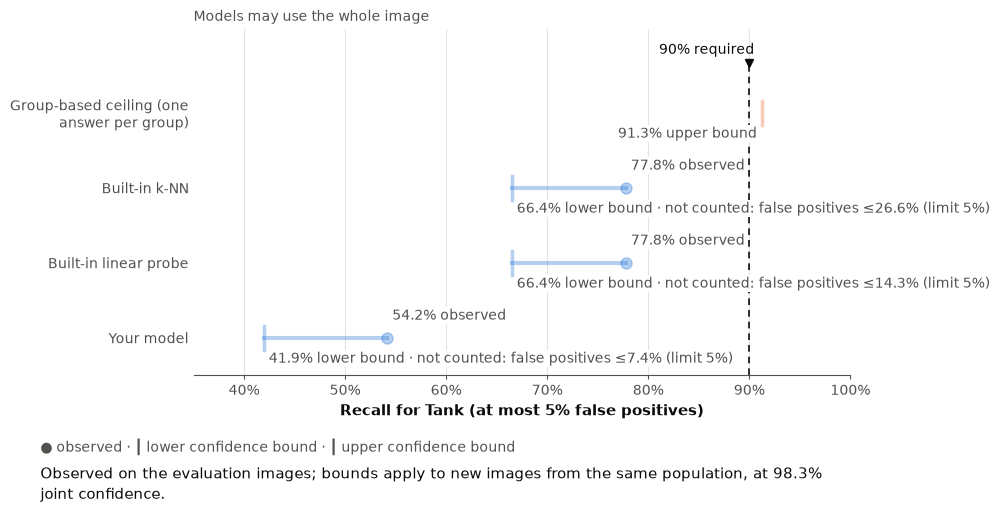

In [24]:
dep.plot(tank_result, plot_evidence=True)